# 2.5 — Three-Method Shape Analysis Comparison

Side-by-side comparison of what each measurement method contributes to the
analysis of cuneiform tablet morphology across three millennia.

| Method | Source | N tablets | What it measures |
|---|---|---|---|
| Physical dimensions | `artifacts.csv` (manual) | ~83,745 | Real-world mm height/width |
| Pixel ratios | `h_w_ratio_df_all.csv` (CV) | ~94,936 | Pixel H/W of largest silhouette component |
| VAE encoding | `vae_encoding_df_*.csv` | ~94,936 | 12 latent shape features |

## Research questions addressed
1. Do all three methods agree on the diachronic portrait-to-landscape trend?
2. Which periods show the most disagreement between physical and pixel ratios
   (= potential composite-image confounds)?
3. What does the VAE reveal that ratio-based methods cannot?
4. How does each method's standardization signal (CV) compare for administrative texts?

**Prerequisites:** Run notebooks 2.2, 2.3, and 2.4 first to generate the
summary CSV files in `paper/figures/`.

In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from scipy.stats import spearmanr

warnings.filterwarnings('ignore', category=FutureWarning)

FIGURES_DIR = 'paper/figures'
ZENODO_BASE = 'https://zenodo.org/records/12787746/files'

plt.rcParams.update({
    'font.family': 'serif', 'font.size': 9,
    'axes.titlesize': 10, 'axes.labelsize': 9,
    'xtick.labelsize': 8, 'ytick.labelsize': 8,
    'legend.fontsize': 8, 'figure.dpi': 150, 'savefig.dpi': 300,
})

PERIOD_CHRON_ORDER = [
    'Uruk IV','Uruk III','Proto-Elamite',
    'ED I-II','ED IIIa','ED IIIb','Ebla',
    'Old Akkadian','Lagash II','Ur III',
    'Early Old Babylonian','Old Babylonian','Old Assyrian',
    'Middle Assyrian','Middle Babylonian','Middle Elamite','Hittite',
    'Neo-Assyrian','Neo-Babylonian','Achaemenid','Hellenistic',
]
MILLENNIUM_ORDER = ['3rd millennium BCE','2nd millennium BCE','1st millennium BCE']
PALETTE = {'3rd millennium BCE':'#4878CF','2nd millennium BCE':'#6ACC65','1st millennium BCE':'#D65F5F'}
THIRD_MIL  = {'Uruk III','Uruk IV','Proto-Elamite','ED I-II','ED IIIa','ED IIIb','Ebla','Old Akkadian','Lagash II','Ur III'}
SECOND_MIL = {'Early Old Babylonian','Old Babylonian','Old Assyrian','Middle Assyrian','Middle Babylonian','Middle Elamite','Hittite'}
def to_millennium(p):
    if p in THIRD_MIL: return '3rd millennium BCE'
    if p in SECOND_MIL: return '2nd millennium BCE'
    return '1st millennium BCE'

print('Setup complete.')

Setup complete.


## 1. Load summary stats from all three methods

In [2]:
# Method 1: Physical dimensions (from notebook 2.2)
phys = pd.read_csv(f'{FIGURES_DIR}/period_summary_stats.csv')
phys = phys.set_index('Period').reindex(PERIOD_CHRON_ORDER).reset_index()
print(f'Physical: {len(phys.dropna())} periods')

# Method 2: Pixel ratios (from notebook 2.3)
pix = pd.read_csv(f'{FIGURES_DIR}/pixel_ratio_summary_stats.csv')
pix = pix.set_index('Period').reindex(PERIOD_CHRON_ORDER).reset_index()
print(f'Pixel:    {len(pix.dropna())} periods')

# Method 3: VAE mean vectors (from notebook 2.4)
vae_means = pd.read_csv(f'{FIGURES_DIR}/vae_period_mean_vectors.csv')
vae_means = vae_means.set_index('Period').reindex(PERIOD_CHRON_ORDER).reset_index()
print(f'VAE:      {len(vae_means.dropna())} periods')

Physical: 21 periods
Pixel:    21 periods
VAE:      21 periods


## 2. Diachronic trend comparison: do all three methods agree?

In [3]:
# Load VAE dimension statistics from notebook 2.4
dim_stats = pd.read_csv(f'{FIGURES_DIR}/vae_dim_stats.csv', index_col='Dimension')

# Identify the top trending dimension empirically (highest |rho|)
top_trend_dim = dim_stats['abs_rho'].idxmax()
top_trend_rho = dim_stats.loc[top_trend_dim, 'rho']
print(f'Top diachronically trending VAE dimension: {top_trend_dim}  (rho={top_trend_rho:.4f})')
print('(Physical shape feature controlled by this dimension: see notebook 12 latent space traversal)')
print()

# Normalise each method's median to Z-scores for overlay comparison
def z_norm(series):
    s = series.dropna()
    return (s - s.mean()) / s.std()

phys_z = z_norm(phys.set_index('Period')['Median']).reindex(PERIOD_CHRON_ORDER)
pix_z  = z_norm(pix.set_index('Period')['Median']).reindex(PERIOD_CHRON_ORDER)

# Top trending VAE dimension: invert sign if rho is negative so positive = more of that feature
# over time matches landscape-increasing convention for direct visual comparison
vae_top_series = vae_means.set_index('Period')[top_trend_dim]
sign = -1 if top_trend_rho < 0 else 1
vae_z = z_norm(sign * vae_top_series).reindex(PERIOD_CHRON_ORDER)

# Spearman rhos
def rho_p(series):
    s = series.dropna()
    idx = [PERIOD_CHRON_ORDER.index(p) + 1 for p in s.index]
    return spearmanr(idx, s.values)

rho_ph, p_ph = rho_p(phys_z)
rho_px, p_px = rho_p(pix_z)
rho_vae, p_vae = rho_p(vae_z)

print('Diachronic Spearman rho (positive = landscape trend over time):')
print(f'  Physical dimensions:    rho={rho_ph:.4f}, p={p_ph:.2e}')
print(f'  Pixel ratios:           rho={rho_px:.4f}, p={p_px:.2e}')
print(f'  VAE {top_trend_dim} (sign-corrected): rho={rho_vae:.4f}, p={p_vae:.2e}')

Top diachronically trending VAE dimension: X2  (rho=0.6545)
(Physical shape feature controlled by this dimension: see notebook 12 latent space traversal)

Diachronic Spearman rho (positive = landscape trend over time):
  Physical dimensions:    rho=-0.7327, p=1.58e-04
  Pixel ratios:           rho=-0.5647, p=7.66e-03
  VAE X2 (sign-corrected): rho=0.6234, p=2.53e-03


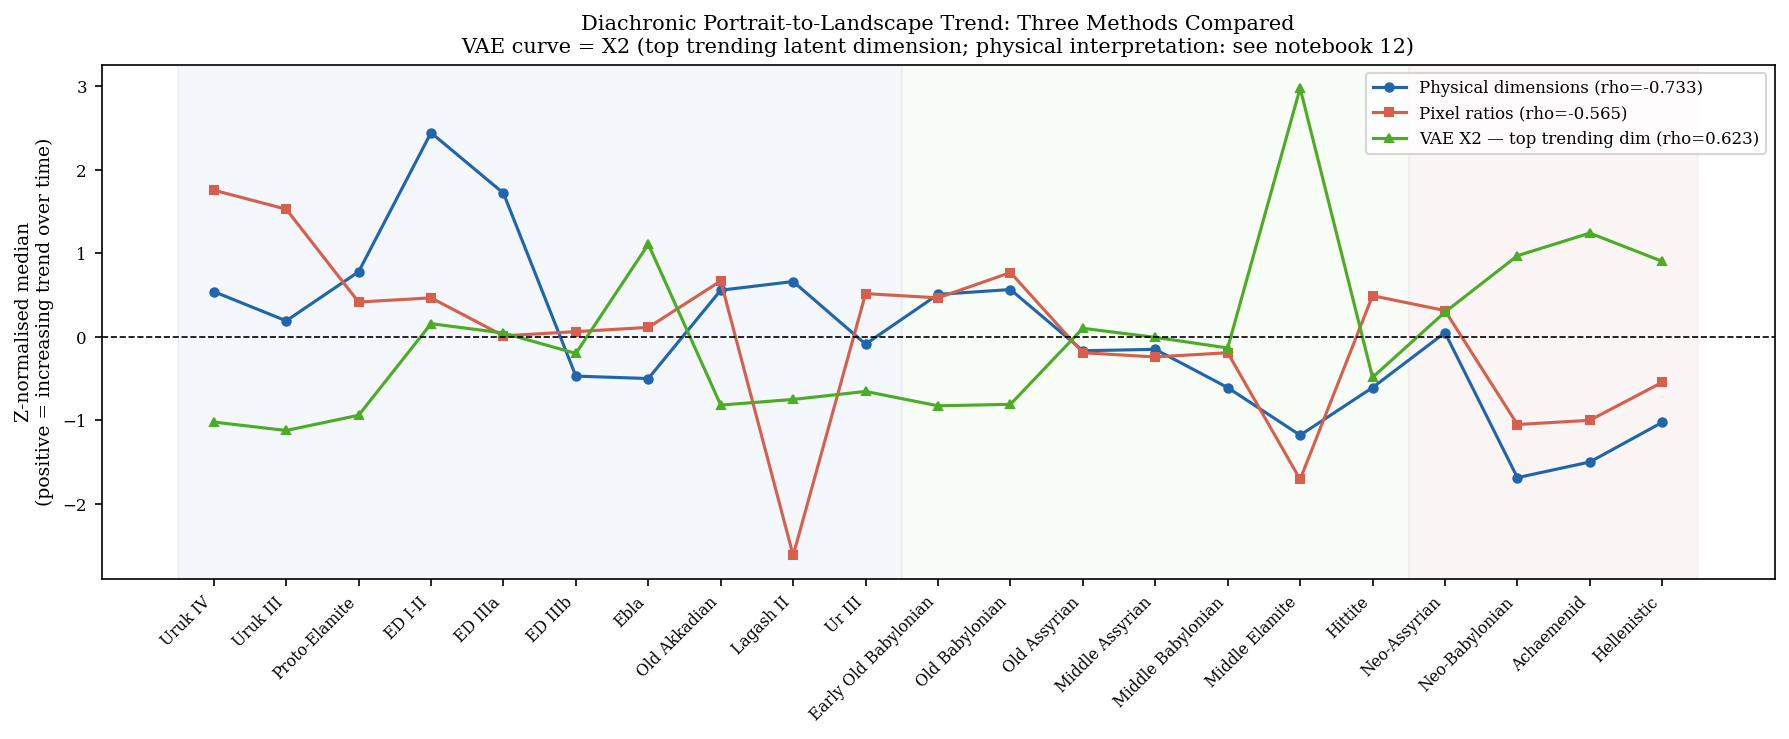

Saved: fig_comparison_diachronic_overlay.pdf


In [4]:
# Overlay figure: diachronic trend across all three methods
x = np.arange(len(PERIOD_CHRON_ORDER))

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(x, phys_z.values, 'o-', color='#2166AC', lw=1.5, ms=4,
        label=f'Physical dimensions (rho={rho_ph:.3f})')
ax.plot(x, pix_z.values, 's-', color='#D6604D', lw=1.5, ms=4,
        label=f'Pixel ratios (rho={rho_px:.3f})')
ax.plot(x, vae_z.values, '^-', color='#4DAC26', lw=1.5, ms=4,
        label=f'VAE {top_trend_dim} — top trending dim (rho={rho_vae:.3f})')
ax.axhline(0, color='black', ls='--', lw=0.8)

# Shade millennia
mil_bounds = []
cur = to_millennium(PERIOD_CHRON_ORDER[0])
start = 0
for i, p in enumerate(PERIOD_CHRON_ORDER):
    m = to_millennium(p)
    if m != cur:
        mil_bounds.append((start, i, cur))
        cur, start = m, i
mil_bounds.append((start, len(PERIOD_CHRON_ORDER), cur))
mil_alpha = {'3rd millennium BCE': 0.06, '2nd millennium BCE': 0.04, '1st millennium BCE': 0.06}
for s, e, m in mil_bounds:
    ax.axvspan(s - 0.5, e - 0.5, alpha=mil_alpha[m], color=PALETTE[m])

ax.set_xticks(x)
ax.set_xticklabels(PERIOD_CHRON_ORDER, rotation=45, ha='right', fontsize=7.5)
ax.set_ylabel('Z-normalised median\n(positive = increasing trend over time)')
ax.set_title(
    f'Diachronic Portrait-to-Landscape Trend: Three Methods Compared\n'
    f'VAE curve = {top_trend_dim} (top trending latent dimension; physical interpretation: see notebook 12)'
)
ax.legend(loc='upper right', fontsize=8)
plt.tight_layout()
plt.savefig(f'{FIGURES_DIR}/fig_comparison_diachronic_overlay.pdf', bbox_inches='tight')
plt.show()
print('Saved: fig_comparison_diachronic_overlay.pdf')

## 3. Method agreement: physical vs. pixel ratio per period

Periods with large divergence between physical and pixel medians are likely
confounded by composite images (obverse+reverse on one canvas).

In [5]:
both = (phys.set_index('Period')[['Median','n']]
        .join(pix.set_index('Period')[['Median','n']], lsuffix='_phys', rsuffix='_pix')
        .reindex(PERIOD_CHRON_ORDER)
        .dropna())

both['diff'] = both['Median_pix'] - both['Median_phys']
both['abs_diff'] = both['diff'].abs()

# Spearman between the two median series
rho_corr, p_corr = spearmanr(both['Median_phys'], both['Median_pix'])
print(f'Spearman correlation between physical and pixel medians: rho={rho_corr:.4f}, p={p_corr:.2e}')
print(f'\nLargest divergences (potential composite-image confounds):')
print(both.sort_values('abs_diff', ascending=False)[['Median_phys','Median_pix','diff','n_phys','n_pix']].head(8).to_string())

Spearman correlation between physical and pixel medians: rho=0.4930, p=2.32e-02

Largest divergences (potential composite-image confounds):
                      Median_phys  Median_pix   diff  n_phys  n_pix
Period                                                             
Lagash II                   1.305        0.50 -0.805     274    594
ED I-II                     1.733        1.11 -0.623     457    234
ED IIIa                     1.559        1.02 -0.539     414    434
Proto-Elamite               1.333        1.10 -0.233    1457    800
Middle Elamite              0.863        0.68 -0.183     601    194
Early Old Babylonian        1.268        1.11 -0.158    2560   1937
Middle Assyrian             1.110        0.97 -0.140    1056   1507
Old Akkadian                1.280        1.15 -0.130    3397   2788


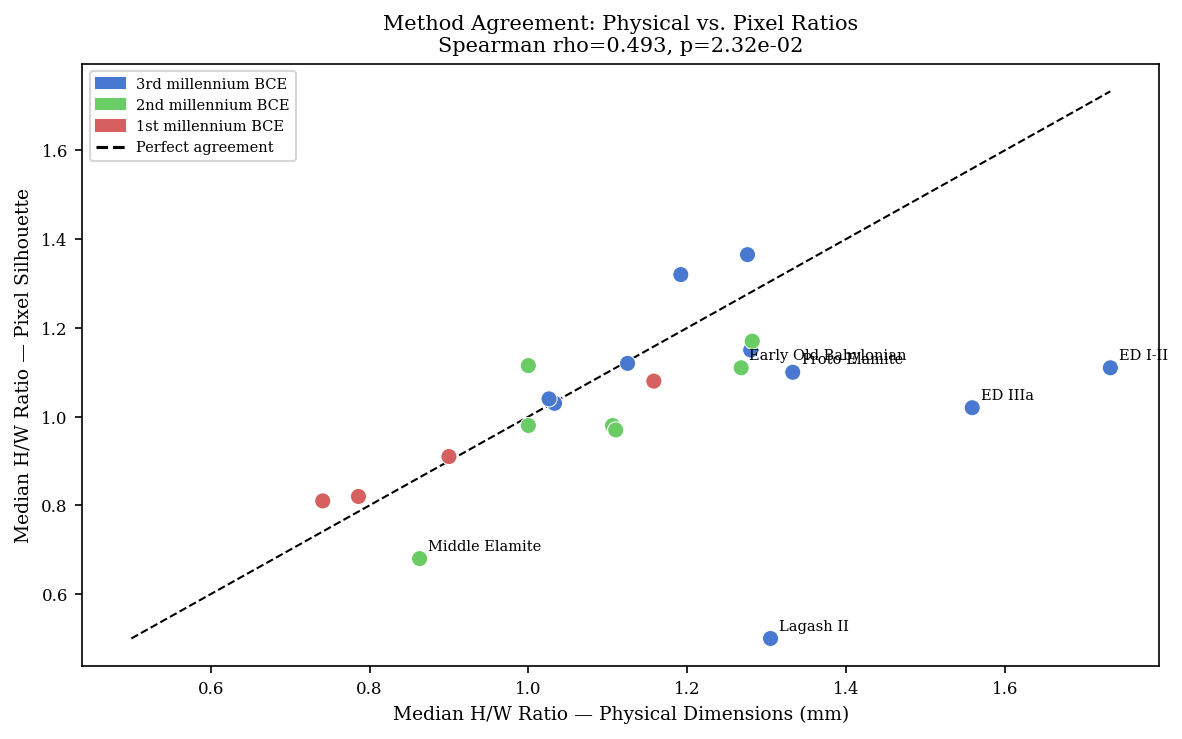

Saved: fig_comparison_phys_vs_pixel.pdf


In [6]:
fig, ax = plt.subplots(figsize=(8, 5))
colors = [PALETTE.get(to_millennium(p), '#888') for p in both.index]
ax.scatter(both['Median_phys'], both['Median_pix'], c=colors, s=60, zorder=3, edgecolors='white', lw=0.5)
# Identity line
lo = min(both[['Median_phys','Median_pix']].min())
hi = max(both[['Median_phys','Median_pix']].max())
ax.plot([lo, hi], [lo, hi], 'k--', lw=1, label='Identity (perfect agreement)')
# Label outliers
for p, row in both.iterrows():
    if row['abs_diff'] > 0.15:
        ax.annotate(p, (row['Median_phys'], row['Median_pix']),
                    fontsize=7, xytext=(4, 4), textcoords='offset points')
ax.set_xlabel('Median H/W Ratio — Physical Dimensions (mm)')
ax.set_ylabel('Median H/W Ratio — Pixel Silhouette')
ax.set_title(f'Method Agreement: Physical vs. Pixel Ratios\nSpearman rho={rho_corr:.3f}, p={p_corr:.2e}')
handles = [mpatches.Patch(color=v, label=k) for k,v in PALETTE.items()]
handles.append(plt.Line2D([0],[0], color='black', ls='--', label='Perfect agreement'))
ax.legend(handles=handles, fontsize=7)
plt.tight_layout()
plt.savefig(f'{FIGURES_DIR}/fig_comparison_phys_vs_pixel.pdf', bbox_inches='tight')
plt.show()
print('Saved: fig_comparison_phys_vs_pixel.pdf')

## 4. What the VAE adds: CV comparison across methods

In [7]:
# Load pixel ratio CV data (from notebook 2.3 output)
pix_cv  = pix.set_index('Period')['CV'].reindex(PERIOD_CHRON_ORDER)
phys_cv = phys.set_index('Period')['CV'].reindex(PERIOD_CHRON_ORDER)

# CV for the top trending VAE dimension (administrative genre)
# Uses raw VAE data; sign does not affect CV (it uses std/|mean|)
print(f'Loading VAE data for CV comparison (using {top_trend_dim} — top trending dimension)...')
dfs = [pd.read_csv(f'{ZENODO_BASE}/vae_encoding_df_April16_w_class_{s}.csv')
       for s in ['train','val','test']]
vae_all = pd.concat(dfs, ignore_index=True)
vae_admin = vae_all[(vae_all['Genre_Name']=='Administrative') &
                    (vae_all['Period_Name'].isin(PERIOD_CHRON_ORDER))]

vae_top_cv = {}
for p in PERIOD_CHRON_ORDER:
    g = vae_admin.loc[vae_admin['Period_Name']==p, top_trend_dim].values
    if len(g) >= 10:
        mean_abs = abs(np.mean(g))
        vae_top_cv[p] = np.std(g, ddof=1) / mean_abs if mean_abs > 0.01 else np.nan
vae_top_cv_s = pd.Series(vae_top_cv).reindex(PERIOD_CHRON_ORDER)

# Three-way CV comparison
cv_compare = pd.DataFrame({
    'Physical (mm)': phys_cv,
    'Pixel ratio': pix_cv,
    f'VAE {top_trend_dim}': vae_top_cv_s,
}).reindex(PERIOD_CHRON_ORDER).dropna(how='all')

print(f'\nCV per period — three methods (administrative genre):')
print(cv_compare.round(3).to_string())

Loading VAE data for CV comparison (using X2 — top trending dimension)...

CV per period — three methods (administrative genre):
                      Physical (mm)  Pixel ratio  VAE X2
Uruk IV                       0.319        0.146   2.291
Uruk III                      0.502        0.294   1.216
Proto-Elamite                 0.279        0.391   1.311
ED I-II                       0.519        0.291  19.204
ED IIIa                       0.406        0.203   4.563
ED IIIb                       0.363        0.315   2.010
Ebla                          0.569        0.486   3.330
Old Akkadian                  0.321        0.306   1.702
Lagash II                     0.605        0.631   1.365
Ur III                        0.251        0.242   1.358
Early Old Babylonian          0.274        0.441   1.661
Old Babylonian                0.342        0.346   3.054
Old Assyrian                  0.536        0.315   5.777
Middle Assyrian               0.500        0.329   3.173
Middle Babylonia

In [8]:
# Rank each period by CV within each method (1 = most standardized)
ranks = cv_compare.rank().round(1)
ranks.columns = [f'Rank ({c})' for c in cv_compare.columns]
ranks['Rank agreement (std)'] = ranks.std(axis=1).round(2)  # low = methods agree
print('CV ranks (1 = most standardized). Low rank-agreement std = methods agree on standardization order.')
print(ranks.to_string())

CV ranks (1 = most standardized). Low rank-agreement std = methods agree on standardization order.
                      Rank (Physical (mm))  Rank (Pixel ratio)  Rank (VAE X2)  Rank agreement (std)
Uruk IV                                4.0                 1.0           10.0                  4.58
Uruk III                              12.0                 5.0            2.0                  5.13
Proto-Elamite                          3.0                14.0            3.0                  6.35
ED I-II                               14.0                 4.0           19.0                  7.64
ED IIIa                                8.0                 2.0           16.0                  7.02
ED IIIb                                7.0                 8.5            8.0                  0.76
Ebla                                  17.0                18.0           15.0                  1.53
Old Akkadian                           5.0                 6.0            7.0                  1.00
L

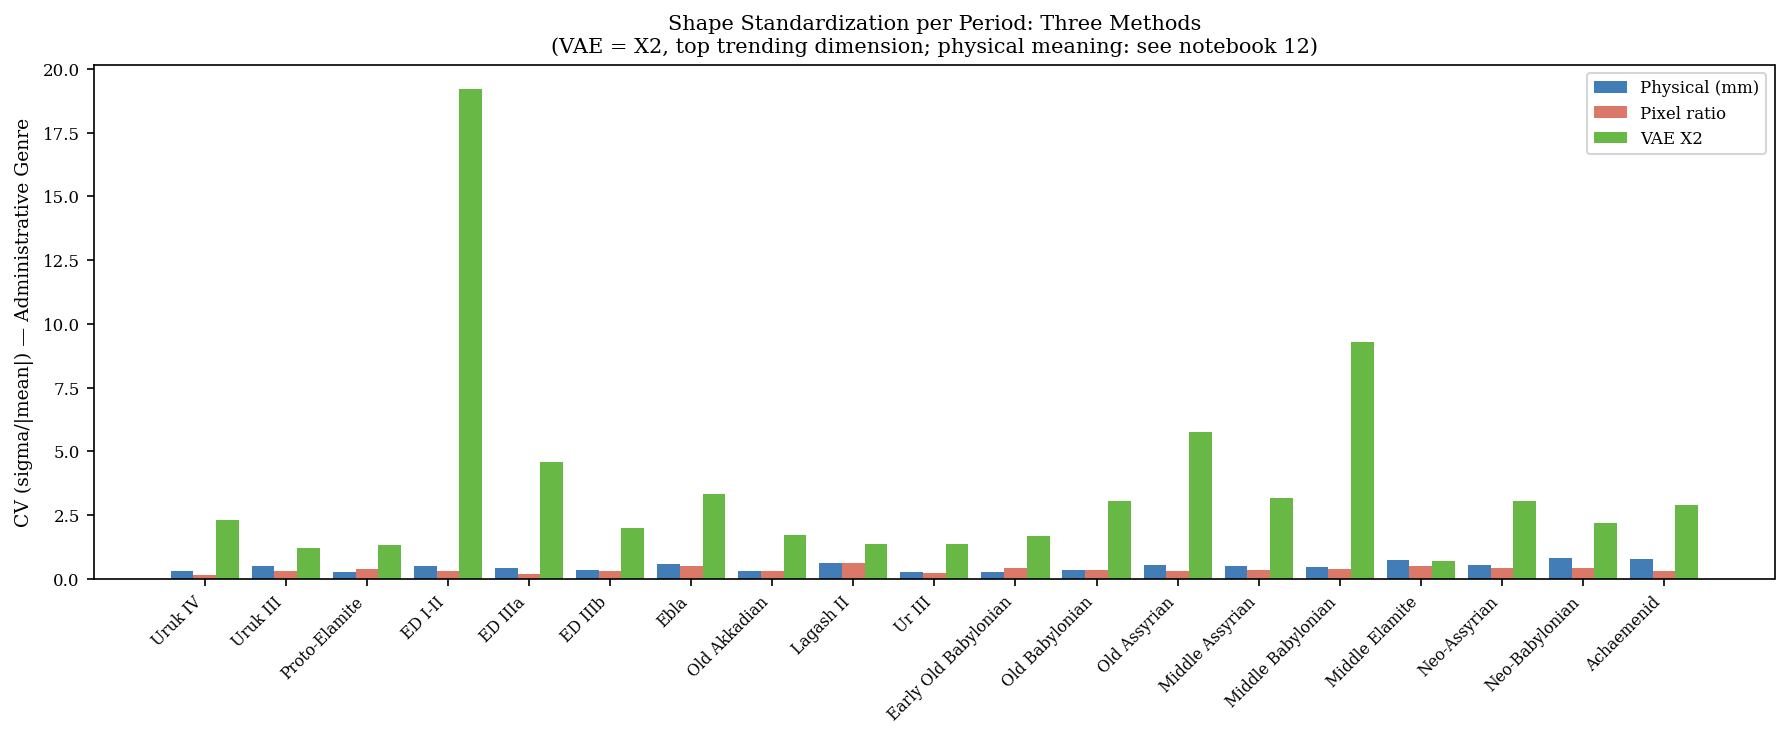

Saved: fig_comparison_cv_three_methods.pdf


In [9]:
# Figure: grouped bar chart comparing CVs
cv_plot = cv_compare.dropna()
cols = cv_plot.columns.tolist()
x = np.arange(len(cv_plot))
w = 0.28
fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(x - w, cv_plot[cols[0]], w, label=cols[0], color='#2166AC', alpha=0.85)
ax.bar(x,     cv_plot[cols[1]], w, label=cols[1], color='#D6604D', alpha=0.85)
ax.bar(x + w, cv_plot[cols[2]], w, label=cols[2], color='#4DAC26', alpha=0.85)
ax.set_xticks(x)
ax.set_xticklabels(cv_plot.index, rotation=45, ha='right', fontsize=7.5)
ax.set_ylabel('CV (sigma/|mean|) — Administrative Genre')
ax.set_title(
    f'Shape Standardization per Period: Three Methods\n'
    f'(VAE = {top_trend_dim}, top trending dimension; physical meaning: see notebook 12)'
)
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(f'{FIGURES_DIR}/fig_comparison_cv_three_methods.pdf', bbox_inches='tight')
plt.show()
print('Saved: fig_comparison_cv_three_methods.pdf')

## 5. Coverage gain: what tablets does computer vision add?

Physical dimensions are available for ~83,745 tablets; the CV pipeline
covers all ~94,936. This cell quantifies per-period coverage gain.

In [10]:
coverage = pd.DataFrame({
    'n_physical': phys.set_index('Period')['n'].reindex(PERIOD_CHRON_ORDER).fillna(0).astype(int),
    'n_pixel':    pix.set_index('Period')['n'].reindex(PERIOD_CHRON_ORDER).fillna(0).astype(int),
}).dropna()
coverage['gain_pct'] = ((coverage['n_pixel'] - coverage['n_physical']) /
                         coverage['n_pixel'] * 100).round(1)

total_phys = coverage['n_physical'].sum()
total_pix  = coverage['n_pixel'].sum()
print(f'Total tablets with physical dimensions: {total_phys:,}')
print(f'Total tablets with pixel ratios:        {total_pix:,}')
print(f'Coverage gain from CV pipeline:         {total_pix - total_phys:,} tablets ({(total_pix-total_phys)/total_pix*100:.1f}%)')
print()
print('Per-period coverage gain (% of pixel-ratio tablets lacking physical dims):')
print(coverage.sort_values('gain_pct', ascending=False).to_string())

Total tablets with physical dimensions: 77,512
Total tablets with pixel ratios:        94,143
Coverage gain from CV pipeline:         16,631 tablets (17.7%)

Per-period coverage gain (% of pixel-ratio tablets lacking physical dims):
                      n_physical  n_pixel  gain_pct
Period                                             
Neo-Assyrian                3379    23406      85.6
Lagash II                    274      594      53.9
Middle Babylonian           3023     6047      50.0
Middle Assyrian             1056     1507      29.9
Old Assyrian                1124     1502      25.2
Ur III                     22504    27849      19.2
Old Babylonian             15884    16814       5.5
ED IIIa                      414      434       4.6
Achaemenid                  1718     1795       4.3
ED IIIb                     1895     1680     -12.8
Old Akkadian                3397     2788     -21.8
Hittite                      161      126     -27.8
Early Old Babylonian        2560     19

In [11]:
print('=== THREE-METHOD COMPARISON SUMMARY ===')
print(f'\nTop trending VAE dimension: {top_trend_dim}  (rho={top_trend_rho:.4f})')
print('(Physical feature controlled: see notebook 12 latent space traversal)')
print('\nDiachronic trend (Spearman rho, landscape direction positive):')
print(f'  Physical (mm):  rho={rho_ph:.4f}, p={p_ph:.2e}')
print(f'  Pixel ratio:    rho={rho_px:.4f}, p={p_px:.2e}')
print(f'  VAE {top_trend_dim}:      rho={rho_vae:.4f}, p={p_vae:.2e}')
print(f'\nPhysical vs. pixel method agreement: rho={rho_corr:.4f}, p={p_corr:.2e}')
print(f'Coverage gain from CV pipeline: +{total_pix-total_phys:,} tablets')
print(f'\nAll comparison figures saved to: {FIGURES_DIR}/')
import glob
for fn in sorted(glob.glob(f'{FIGURES_DIR}/fig_comparison*.pdf')):
    print(f'  {os.path.basename(fn)}')

=== THREE-METHOD COMPARISON SUMMARY ===

Top trending VAE dimension: X2  (rho=0.6545)
(Physical feature controlled: see notebook 12 latent space traversal)

Diachronic trend (Spearman rho, landscape direction positive):
  Physical (mm):  rho=-0.7327, p=1.58e-04
  Pixel ratio:    rho=-0.5647, p=7.66e-03
  VAE X2:      rho=0.6234, p=2.53e-03

Physical vs. pixel method agreement: rho=0.4930, p=2.32e-02
Coverage gain from CV pipeline: +16,631 tablets

All comparison figures saved to: paper/figures/
  fig_comparison_cv_three_methods.pdf
  fig_comparison_diachronic_overlay.pdf
  fig_comparison_phys_vs_pixel.pdf
